In [ ]:
import json
import os

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

folder = "disprot-2025_12_12"
filename = "DisProt-release_2025_12-with_ambiguous_evidences.json"
# downloaded from https://disprot.org/download
with open(os.path.join(folder, filename), encoding="utf-8") as f:
    data = json.load(f)
print(f"DisProt size: {data['size']:_}")

# fix wrongly assinged disorder_content
for i in range(len(data["data"])):
    d = data["data"][i]
    disorder_array = np.zeros(d["length"])
    for annotation in d["disprot_consensus"]["Structural state"]:
        if annotation["type"] == "D":
            disorder_array[annotation["start"] - 1 : annotation["end"]] = 1
    if np.mean(disorder_array) != d["disorder_content"]:
        print("  Fixed:", d["disprot_id"], np.mean(disorder_array), d["disorder_content"])
        data["data"][i]["disorder_content"] = np.mean(disorder_array)

print("\nRandom example:")
d = data["data"][np.random.randint(0, len(data["data"]))]
d["disprot_id"], d["disorder_content"], d["length"], d["sequence"], d["disprot_consensus"]

DisProt size: 3_199
  Fixed: DP00123 0.08296943231441048 0.13537117903930132
  Fixed: DP00549 0.5522388059701493 0.8656716417910447
  Fixed: DP01351 0.42696629213483145 0.6292134831460674
  Fixed: DP02148 0.042833607907743 0.0757825370675453

Random example:


('DP00222',
 1,
 720,
 'MAKRVADAQIQRETYDSNESDDDVTPSTKVASSAVMNRRKIAMPKRRMAFKPFGSAKSDETKQASSFSFLNRADGTGEAQVDNSPTTESNSRLKALNLQFKAKVDDLVLGKPLADLRPLFTRYELYIKNILEAPVKSIENPTQTKGNDAKPAKVEDVQKSSDSSSEDEVKVEGPKFTIDAKPPISDSVFSFGPKKENRKKDESDSENDIEIKGPEFKFSGTVSSDVFKLNPSTDKNEKKTETNAKPFSFSSATSTTEQTKSKNPLSLTEATKTNVDNNSKAEASFTFGTKHAADSQNNKPSFVFGQAAAKPSLEKSSFTFGSTTIEKKNDENSTSNSKPEKSSDSNDSNPSFSFSIPSKNTPDASKPSFSFGVPNSSKNETSKPVFSFGAATPSAKEASQEDDNNNVEKPSSKPAFNLISNAGTEKEKESKKDSKPAFSFGISNGSESKDSDKPSLPSAVDGENDKKEATKPAFSFGINTNTTKTADTKAPTFTFGSSALADNKEDVKKPFSFGTSQPNNTPSFSFGKTTANLPANSSTSPAPSIPSTGFKFSLPFEQKGSQTTTNDSKEESTTEATGNESQDATKVDATPEESKPINLQNGEEDEVALFSQKAKLMTFNAETKSYDSRGVGEMKLLKKKDDPSKVRLLCRSDGMGNVLLNATVVDSFKYEPLAPGNDNLIKAPTVAADGKLVTYIVKFKQKEEGRSFTKAIEDAKKEMK',
 {'full': [{'start': 1, 'end': 720, 'type': 'D'}],
  'Structural state': [{'start': 1, 'end': 720, 'type': 'D'}],
  'Molecular function': [{'start': 1, 'end': 720, 'type': 'F'}],
  'Disorder function': [{'start': 185, 'end': 527, 'type': 'F'}]})

In [2]:
filename = "trizod-2025_12_12/tolerant-dataset_new.csv"
df = pd.read_csv(filename, index_col="label", converters={"gscores": lambda x: np.array(json.loads(x), dtype=float)})
df

,entity_name,cluster_size,sequence,temperature,pH,ionic_strength,total_bbshifts,mean_gscore,gscores
label,,,,,,,,,
9_1_1_1,carboxypeptidase inhibitor,3,XQHADPICNKPCKTHDDCSGAWFCQACWNSARTCGPYVG,308.00,3.82,0.1000,102.0,0.090743,"[nan, 0.2454, 0.3479, 0.3993, 0.3947, 0.2264, ..."
26_1_1_1,glycoprotein D-1,1,MADPNRFRGKDLPVLDQLTDPP,293.00,4.70,0.1000,55.0,0.706490,"[nan, 0.8055, 0.7937, 0.6111, 0.3137, 0.4028, ..."
32_1_1_1,lac repressor headpiece,9,MKPVTLYDVAEYAGVSYQTVSRVVNQASHVSAKTREKVEAAMAELN...,291.00,6.85,0.1000,121.0,0.123321,"[nan, nan, 0.1458, 0.0797, 0.0859, 0.0887, 0.1..."
39_1_1_1,metallothionein-2,5,XMDPNCSCATDGSCSCAGSCKCKQCKKTSCKKSCCSCCPVGCAKCS...,298.00,7.00,0.1000,146.0,0.133115,"[nan, 0.3863, 0.406, 0.1919, 0.1133, 0.0301, 0..."
41_1_1_1,neutrophil NP-5,1,VFCTCRGFLCGSGERASGSCTINGVRHTLCCRR,293.00,3.50,0.1000,88.0,0.103945,"[nan, 0.1615, 0.1117, 0.1094, 0.0774, 0.1508, ..."
...,...,...,...,...,...,...,...,...,...
53396_1_1_1,entity_1,1,GSDQSENVDRGAGSIREAGGAFGKREQAEEERYFRAQSREQLAALK...,310.15,5.30,0.2090,523.0,0.331722,"[nan, 0.3723, 0.2999, 0.3817, 0.4018, 0.6082, ..."
53398_1_1_1,entity_1,1,PAGQPERTLESLLAHLQEQHGLRVRILLHGSALLYAAGWSPEKQAQ...,293.15,7.40,0.1000,443.0,0.081394,"[nan, 0.0482, 0.0643, 0.1115, 0.0818, 0.0556, ..."
53400_1_1_1,entity_1,1,KCGSLGNIHHKPGGGQVEVKSEKLDFKDRVQSKIGSLDNITHVPGG...,298.00,7.40,0.1617,238.0,0.854909,"[nan, nan, nan, 0.9551, 0.9564, 0.7819, 0.6935..."


In [ ]:
filename_tag = "DisProt+TriZOD"
if not os.path.exists(os.path.join(folder, filename_tag + "_rep_seq.fasta")):
    with open(os.path.join(folder, filename_tag + ".fasta"), "w") as f:
        for d in data["data"]:
            f.write(f">{d['disprot_id']}\n{d['sequence']}\n")
        for label, d in df.iterrows():
            f.write(f">{label}\n{d['sequence']}\n")
    import subprocess

    # Build the docker command
    docker_cmd = [
        "docker",
        "run",
        "--rm",
        "--user",
        f"{os.getuid()}:{os.getgid()}",
        "-v",
        f"{os.path.abspath(folder)}:/data",
        "-w",
        "/data",
        "ghcr.io/soedinglab/mmseqs2",
        "easy-cluster",
        filename_tag + ".fasta",
        filename_tag,
        "/tmp",
    ]
    subprocess.run(docker_cmd, check=True)
    os.remove(os.path.join(folder, filename_tag + ".fasta"))

easy-cluster DisProt+TriZOD.fasta DisProt+TriZOD /tmp 

MMseqs Version:                     	8cc5ce367b5638c4306c2d7cfc652dd099a4643f
Substitution matrix                 	aa:blosum62.out,nucl:nucleotide.out
Seed substitution matrix            	aa:VTML80.out,nucl:nucleotide.out
Sensitivity                         	4
k-mer length                        	0
Target search mode                  	0
k-score                             	seq:2147483647,prof:2147483647
Alphabet size                       	aa:21,nucl:5
Max sequence length                 	65535
Max results per query               	20
Split database                      	0
Split mode                          	2
Split memory limit                  	0
Coverage threshold                  	0.8
Coverage mode                       	0
Compositional bias                  	1
Compositional bias scale            	1
Diagonal scoring                    	true
Exact k-mer matching                	0
Mask residues                       	1
Mask resi

In [4]:
clusters_df = pd.read_csv(f"{folder}/{filename_tag}_cluster.tsv", sep="\t", names=["representative", "member"])
cluster_sizes = clusters_df.groupby("representative").size()
clusters_df["cluster_size"] = clusters_df["representative"].map(cluster_sizes)

# Find clusters with at least one member containing "DP" and one containing "_"
has_dp = clusters_df.groupby("representative")["member"].apply(lambda x: x.str.contains("DP").any())
has_underscore = clusters_df.groupby("representative")["member"].apply(lambda x: x.str.contains("_").any())
shared_clusters = has_dp & has_underscore
print(f"{len(clusters_df['representative'].unique()):_} total clusters")
print(f"{sum(has_dp):_} from disprot")
print(f"{sum(has_underscore):_} from trizod")
print(f"  {sum(shared_clusters):_} shared")

shared_clusters_df = clusters_df[clusters_df["representative"].isin(shared_clusters[shared_clusters].index)]

9_030 total clusters
2_556 from disprot
6_777 from trizod
  303 shared


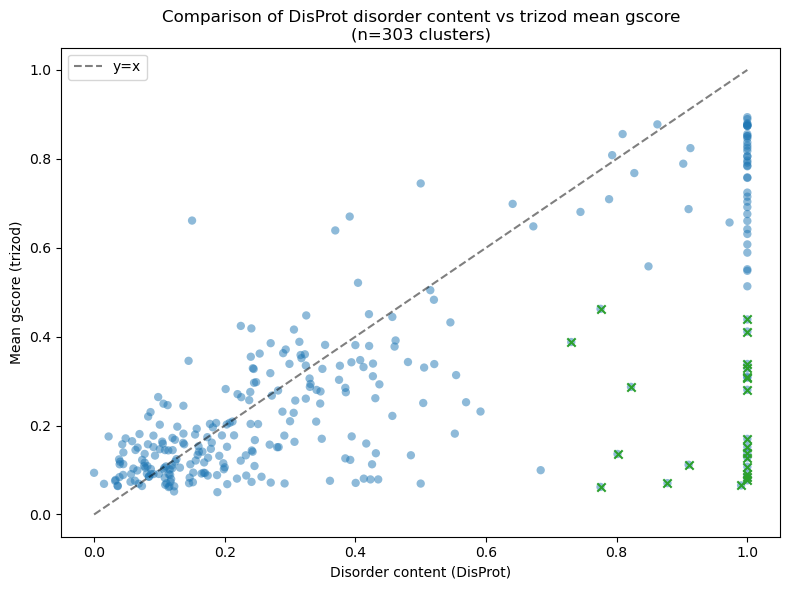

trizod only disorder: 0
disprot only disorder: 23


In [ ]:
# Create a lookup for disorder_content by disprot_id
disprot_disorder = {d["disprot_id"]: d["disorder_content"] for d in data["data"]}

# For each representative, get mean_gscore from a "_" member and disorder_content from a "DP" member
mean_gscores = []
disorder_contents = []
trizod_members = []
disprot_members = []

for _, group in shared_clusters_df.groupby("representative"):
    disorder_contents_g = []
    mean_gscores_g = []
    trizod_members.append([])
    disprot_members.append([])
    for m in group["member"]:
        if m.startswith("DP"):
            disorder_contents_g.append(disprot_disorder[m])
            disprot_members[-1].append(m)
        else:
            mean_gscores_g.append(df.loc[m, "mean_gscore"])
            trizod_members[-1].append(m)
    disorder_contents.append(np.mean(disorder_contents_g))
    mean_gscores.append(np.mean(mean_gscores_g))

mean_gscores = np.array(mean_gscores)
disorder_contents = np.array(disorder_contents)

# Scatterplot
plt.figure(figsize=(8, 6))
plt.scatter(disorder_contents, mean_gscores, alpha=0.5, edgecolors="none")
plt.xlabel("Disorder content (DisProt)")
plt.ylabel("Mean gscore (trizod)")
plt.title(f"Comparison of DisProt disorder content vs trizod mean gscore\n(n={len(mean_gscores)} clusters)")
plt.plot([0, 1], [0, 1], "k--", alpha=0.5, label="y=x")
plt.legend()
unc_region = 0.2
trizod_only_disorder = (mean_gscores >= 0.5 + unc_region) & (disorder_contents < 0.5)
plt.scatter(disorder_contents[trizod_only_disorder], mean_gscores[trizod_only_disorder], marker="x")
disprot_only_disorder = (mean_gscores < 0.5) & (disorder_contents >= 0.5 + unc_region)
plt.scatter(disorder_contents[disprot_only_disorder], mean_gscores[disprot_only_disorder], marker="x")
plt.tight_layout()
plt.show()

print(f"trizod only disorder: {sum(trizod_only_disorder)}")
print(f"disprot only disorder: {sum(disprot_only_disorder)}")


In [ ]:
# disprot disorder annotations seem to be more reliable
mask = (disorder_contents > 0.8) & (mean_gscores < 0.5)
print("Mismatching entries:\n")
wrong_trizod = []
for i in np.where(mask)[0]:
    print(
        f"DisProt: {disprot_members[i]}, trizod: {trizod_members[i]}, disorder_content: {disorder_contents[i]:.2f}, mean_gscore: {mean_gscores[i]:.3f}",
    )
    wrong_trizod.extend(trizod_members[i])
print(f"\nRemoving {len(wrong_trizod)} wrong trizod entries")
cleaned_clusters_df = clusters_df[~clusters_df["member"].isin(wrong_trizod)].copy()
cleaned_trizod_df = df[~df.index.isin(wrong_trizod)].copy()
len(cleaned_clusters_df), len(clusters_df)

Mismatching entries:

DisProt: ['DP03647'], trizod: ['10073_1_1_1'], disorder_content: 0.80, mean_gscore: 0.136
DisProt: ['DP04271'], trizod: ['15093_1_1_1'], disorder_content: 0.91, mean_gscore: 0.112
DisProt: ['DP01637'], trizod: ['15789_1_1_1'], disorder_content: 0.82, mean_gscore: 0.287
DisProt: ['DP02010'], trizod: ['25401_1_1_1'], disorder_content: 1.00, mean_gscore: 0.308
DisProt: ['DP00006'], trizod: ['25640_1_1_1'], disorder_content: 0.99, mean_gscore: 0.065
DisProt: ['DP00592'], trizod: ['25796_2_2_2'], disorder_content: 1.00, mean_gscore: 0.170
DisProt: ['DP03818'], trizod: ['34283_1_1_1'], disorder_content: 1.00, mean_gscore: 0.077
DisProt: ['DP02267'], trizod: ['36009_1_1_1'], disorder_content: 1.00, mean_gscore: 0.128
DisProt: ['DP00340'], trizod: ['5578_1_1_1', '18632_1_1_1'], disorder_content: 1.00, mean_gscore: 0.084
DisProt: ['DP00626'], trizod: ['6373_1_1_1'], disorder_content: 1.00, mean_gscore: 0.107
DisProt: ['DP00070', 'DP00555', 'DP00630'], trizod: ['5744_1_1_1'

(10066, 10087)

In [ ]:
def calc_mean_disorder(label):
    if "DP" in label:
        return disprot_disorder[label]
    else:
        return df.loc[label, "mean_gscore"]


cleaned_clusters_df["average_disorder"] = cleaned_clusters_df["member"].map(calc_mean_disorder)

mean_disorder = cleaned_clusters_df.groupby("representative")["average_disorder"].mean()
std_disorder = cleaned_clusters_df.groupby("representative")["average_disorder"].std()

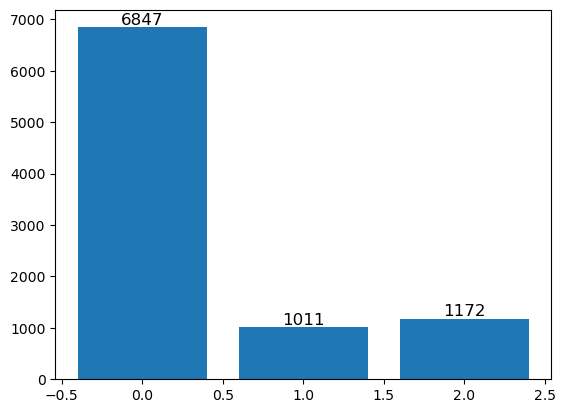

In [ ]:
std_disorder_threshold = 0.25
mean_disorder_threshold = 0.5

classes = {}  # 0: ordered, 1: disordered, 2: middle
for _, group in cleaned_clusters_df.groupby("representative"):
    mean_dis = []
    std_dis = []
    for label in group["member"]:
        if label.startswith("DP"):
            mean_dis.append(disprot_disorder[label])
        else:
            mean_dis.append(cleaned_trizod_df.loc[label, "mean_gscore"])
            std_dis.append(np.nanstd(cleaned_trizod_df.loc[label, "gscores"]))
    if (std_dis and np.mean(std_dis) > std_disorder_threshold) or (np.std(mean_dis) > std_disorder_threshold):
        classes[group["representative"].iloc[0]] = 2
    else:
        classes[group["representative"].iloc[0]] = int(np.mean(mean_dis) >= mean_disorder_threshold)

counts = np.bincount(list(classes.values()))
labels = np.unique(list(classes.values()))
bars = plt.bar(labels, counts)
for bar, count in zip(bars, counts):
    plt.text(bar.get_x() + bar.get_width() / 2, bar.get_height(), str(count), ha="center", va="bottom", fontsize=12)
plt.show()


In [ ]:
np.random.seed(883)
test_percentage = 0.1
test_ids = {}
dis_mask = cleaned_trizod_df["mean_gscore"] >= 0.5
half_test = int(sum(dis_mask) * test_percentage)
print(f"n_test: {2 * half_test}")
test_indexes = np.concatenate(
    [
        np.random.choice(cleaned_trizod_df.index[dis_mask], size=half_test, replace=False),
        np.random.choice(cleaned_trizod_df.index[~dis_mask], size=half_test, replace=False),
    ],
)
cleaned_trizod_df["is_test"] = False
cleaned_trizod_df.loc[test_indexes, "is_test"] = True

cleaned_trizod_df.assign(gscores=cleaned_trizod_df["gscores"].apply(lambda x: json.dumps(x.tolist()))).to_csv(
    "cleaned_trizod_dataset.csv",
)

n_test: 160


In [10]:
disprot_seqs = {d["disprot_id"]: d["sequence"] for d in data["data"]}

with open("st_classes.csv", "w") as f:
    f.write("label,is_test,class,sequence\n")
    for _, group in cleaned_clusters_df.groupby("representative"):
        is_test = False
        for label in group["member"]:
            if label in test_indexes:
                is_test = True
                break
        label = group["representative"].iloc[0]
        if label.startswith("DP"):
            seq = disprot_seqs[label]
        else:
            seq = df.loc[label, "sequence"]
        f.write(f"{label},{is_test},{classes[label]},{seq}\n")

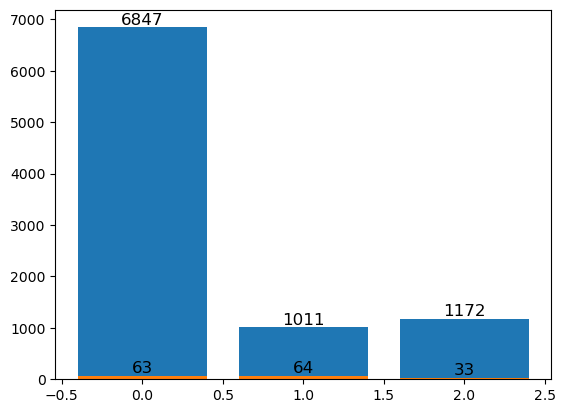

In [ ]:
classes_df = pd.read_csv("st_classes.csv")

counts = np.bincount(list(classes_df["class"].values))
labels = np.unique(list(classes_df["class"].values))
bars = plt.bar(labels, counts)
for bar, count in zip(bars, counts):
    plt.text(bar.get_x() + bar.get_width() / 2, bar.get_height(), str(count), ha="center", va="bottom", fontsize=12)
counts = np.bincount(list(classes_df[classes_df["is_test"]]["class"].values))
labels = np.unique(list(classes_df[classes_df["is_test"]]["class"].values))
bars = plt.bar(labels, counts)
for bar, count in zip(bars, counts):
    plt.text(bar.get_x() + bar.get_width() / 2, bar.get_height(), str(count), ha="center", va="bottom", fontsize=12)